# Lab: generate handwritten digits with a VAE

**Data:** MNIST · **Images:** 28 × 28 grayscale · **Latent dimension:** 32

We train a fully connected variational autoencoder, inspect held-out reconstructions,
and **generate new digit images by sampling latent vectors from a standard normal distribution**.
The architecture is **784 → 512 → 32 → 512 → 784**, with separate encoder heads for the
32-dimensional posterior mean and log variance.

This lab follows the same sequence as the CelebA VAE lab: setup, data, model, loss,
training, learning curves, reconstruction, and generation. It retains the fully connected
architecture and Gaussian observation model from the original MNIST VAE notebook.
Digit labels are used only to label figures and choose display examples, never to train the model.

By the end, you should be able to explain the two encoder heads, implement reparameterization
and the KL penalty, and distinguish reconstruction from generation.

**Run guide.** Run the cells from top to bottom in Jupyter or Colab. A GPU is optional for this
small model. The first run downloads MNIST. The default run uses 55,000 training images for
50 epochs, with separate validation and test sets. `QUICK_RUN=True` runs a shorter execution
check; use the default setting for the main experiment. Training time and image quality depend
on the hardware and fitted model. Output cells belong to the configuration used when executed;
rerun all cells after changing settings.

**Included outputs.** This copy was executed on CPU with the default settings: 50 epochs, 55,000 training images, and latent dimension 32. Validation selected epoch 50. The reconstruction and generation figures below were computed from that trained model.


## 1. Setup and experiment settings

The next cell installs only missing packages and leaves an existing PyTorch installation in place.
An existing PyTorch/torchvision pair must be compatible.


In [1]:
import importlib.util
import subprocess
import sys

packages = ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'tqdm']
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are available.')


All required packages are available.


In [2]:
import json
import math
import os
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
    # A modest thread count avoids excess overhead for these small matrix products.
    torch.set_num_threads(min(4, os.cpu_count() or 1))

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('PyTorch:', torch.__version__, '| device:', device)
# Fixed seeds improve repeatability; different hardware may still give different results.


PyTorch: 2.7.0 | device: mps


Keep `HIDDEN_DIM=512` and `LATENT_DIM=32` for the requested architecture. Each encoder head
has 32 outputs; the latent vector itself has 32 coordinates.

`OBS_VAR` is the fixed Gaussian observation variance, and `BETA=1` gives the ordinary VAE
objective described in Section 4. These settings retain the original MNIST notebook's loss.
`LOAD_CHECKPOINT` reuses a checkpoint from this notebook instead of training again.
Each run writes its figures, metrics, settings, and checkpoints to a new output directory.


In [3]:
SEED = 42
QUICK_RUN = False
IMAGE_SIZE = 28
LATENT_DIM = 32
HIDDEN_DIM = 512
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
LR_DECAY = 0.95
OBS_VAR = 0.5                     # Variance, not standard deviation.
BETA = 1.0

EPOCHS = 5 if QUICK_RUN else 50
TRAIN_LIMIT = 10_000 if QUICK_RUN else None
VAL_SIZE = 5_000
NUM_WORKERS = 0                   # Portable default for notebooks.
DATA_ROOT = Path('./data')
DOWNLOAD = True
LOAD_CHECKPOINT = None            # Example: Path('outputs/.../best_vae.pt')

SHOW_PROGRESS = False            # True adds a minibatch progress bar.
SAVE_EVERY = 5
SAMPLE_SEED = 2026
OUTPUT_ROOT = Path('./outputs')
RUN_DIR = OUTPUT_ROOT / f'mnist_vae_d{LATENT_DIM}_{datetime.now():%Y%m%d_%H%M%S_%f}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert IMAGE_SIZE == 28 and HIDDEN_DIM == 512
assert isinstance(LATENT_DIM, int) and LATENT_DIM > 0
assert OBS_VAR > 0 and BETA > 0
assert EPOCHS >= 1 and BATCH_SIZE >= 1 and SAVE_EVERY >= 1
seed_everything(SEED)
print(f'Architecture: 784 → {HIDDEN_DIM} → {LATENT_DIM} → {HIDDEN_DIM} → 784')
print(f'Epochs: {EPOCHS} | observation variance: {OBS_VAR} | beta: {BETA}')
print('Outputs:', RUN_DIR.resolve())


Architecture: 784 → 512 → 32 → 512 → 784
Epochs: 50 | observation variance: 0.5 | beta: 1.0
Outputs: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_vae_d32_20261015_085833_250239


## 2. Load MNIST

Split the original 60,000 training images into **55,000 training** and **5,000 validation**
images using a fixed random permutation. Keep the official **10,000 test** images separate.
Quick mode uses 10,000 images from the training split and leaves validation and test unchanged.

`ToTensor()` produces tensors of shape `(1, 28, 28)` with intensities in $[0,1]$.
Pixels are neither standardized nor binarized. Each `DataLoader` supplies minibatches;
`for x, _ in loader` ignores labels during fitting and evaluation of the objective.


In [4]:
mnist_train = datasets.MNIST(DATA_ROOT, train=True, download=DOWNLOAD,
                             transform=transforms.ToTensor())
mnist_test = datasets.MNIST(DATA_ROOT, train=False, download=DOWNLOAD,
                            transform=transforms.ToTensor())

split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(mnist_train), generator=split_generator)
val_indices = permutation[:VAL_SIZE].tolist()
train_indices = permutation[VAL_SIZE:].tolist()
if TRAIN_LIMIT is not None:
    train_indices = train_indices[:TRAIN_LIMIT]

train_data = Subset(mnist_train, train_indices)
val_data = Subset(mnist_train, val_indices)
test_data = mnist_test

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))
val_loader = DataLoader(val_data, batch_size=512, shuffle=False,
                        num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=512, shuffle=False,
                         num_workers=NUM_WORKERS)

print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')


Train: 55,000; validation: 5,000; test: 10,000


Batch shape: (512, 1, 28, 28) | range: 0.0 1.0


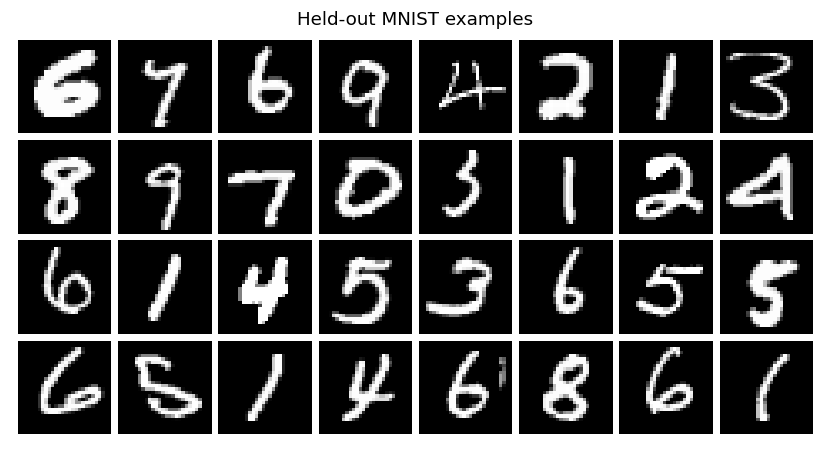

In [5]:
def show_digits(images, title, nrow=8, filename=None):
    images = images.detach().cpu()
    grid = make_grid(images, nrow=nrow, padding=2, pad_value=1)
    fig, ax = plt.subplots(figsize=(min(nrow, 8), math.ceil(len(images) / nrow)),
                            layout='constrained')
    ax.imshow(grid[0].numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
    if filename is not None:
        fig.savefig(filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


preview_images, _ = next(iter(val_loader))
print('Batch shape:', tuple(preview_images.shape), '| range:',
      float(preview_images.min()), float(preview_images.max()))
show_digits(preview_images[:32], 'Held-out MNIST examples')


## 3. The fully connected VAE

The encoder represents a diagonal Gaussian,
$$
q_\phi(z\mid x)=\mathcal N\!\left(\mu_\phi(x),
\operatorname{diag}\{\exp(\ell_\phi(x))\}\right),
\qquad \ell_\phi(x)=\log\sigma_\phi^2(x).
$$
The mean and log-variance heads each return 32 numbers. They parameterize one distribution
over a **32-dimensional** latent vector. Reparameterization draws
$$
\epsilon\sim\mathcal N(0,I_{32}),\qquad
z=\mu_\phi(x)+\exp\{\ell_\phi(x)/2\}\odot\epsilon.
$$
Gradients reach the encoder through this expression. `logvar` is log **variance**,
so `exp(0.5 * logvar)` gives the posterior standard deviation.

| Stage | Operation | Shape, omitting batch dimension |
|---|---|---|
| Input | Flatten | $1\times28\times28\to784$ |
| Encoder hidden layer | Linear + ReLU | $784\to512$ |
| Two encoder heads | Separate linear layers | $\mu\in\mathbb R^{32}$, $\ell\in\mathbb R^{32}$ |
| Reparameterization | Posterior draw | $z\in\mathbb R^{32}$ |
| Decoder hidden layer | Linear + ReLU | $32\to512$ |
| Decoder output | Linear + Sigmoid, then reshape | $512\to784\to1\times28\times28$ |

The decoder receives only $z$ and returns a conditional mean image in $[0,1]$.
The Gaussian observation model is
$$p_\theta(x\mid z)=\mathcal N\!\left(g_\theta(z),\tau^2 I_{784}\right),
\qquad \tau^2=\texttt{OBS\_VAR}.$$
The encoder learns posterior variances; the observation variance $\tau^2$ is fixed.
The sigmoid bounds the conditional mean, while the Gaussian observation distribution itself
has support on all of $\mathbb R^{784}$.


In [6]:
class VanillaVAE(nn.Module):
    def __init__(self, latent_dim=32, hidden_dim=512):
        super().__init__()
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x)
        return self.fc_mu(features), self.fc_logvar(features)

    @staticmethod
    def reparameterize(mu, logvar, eps=None):
        if eps is None:
            eps = torch.randn_like(mu)
        return mu + torch.exp(0.5 * logvar) * eps

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar


In [7]:
seed_everything(SEED)
model = VanillaVAE(LATENT_DIM, HIDDEN_DIM).to(device)
model.eval()
with torch.inference_mode():
    dummy = torch.zeros(2, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)
    dummy_out, dummy_mu, dummy_logvar = model(dummy, sample=False)
assert dummy_mu.shape == dummy_logvar.shape == (2, LATENT_DIM)
assert dummy_out.shape == dummy.shape
print(model)
print('Input:', tuple(dummy.shape))
print('mu:', tuple(dummy_mu.shape), '| log variance:', tuple(dummy_logvar.shape))
print('Reconstruction:', tuple(dummy_out.shape))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
del dummy, dummy_out, dummy_mu, dummy_logvar


VanillaVAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=512, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=512, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Input: (2, 1, 28, 28)
mu: (2, 32) | log variance: (2, 32)
Reconstruction: (2, 1, 28, 28)
Trainable parameters: 853,840


## 4. Reconstruction loss and KL divergence

For image $i$, with one reparameterized draw $z_i\sim q_\phi(z\mid x_i)$, define
$$
R_i=\frac{1}{2\tau^2}\sum_{p=1}^{784}\{x_{ip}-g_\theta(z_i)_p\}^2,
\qquad
K_i=\frac12\sum_{j=1}^{32}
\{\mu_{ij}^2+\exp(\ell_{ij})-1-\ell_{ij}\}.
$$
The minibatch objective is
$$\mathcal L=\frac1B\sum_{i=1}^B(R_i+\beta K_i),
\qquad \beta=\texttt{BETA}.$$
For $\beta=1$, this estimates the negative ELBO **up to the fixed Gaussian normalizing
constant** $\tfrac{784}{2}\log(2\pi\tau^2)$. With $\tau^2=0.5$, $R_i$ equals the pixel
**sum of squared errors**. The KL is summed over latent coordinates. Both are averaged
over images, including the smaller final minibatch with its correct weight.

We also report pixel MSE, $\|x_i-g_\theta(z_i)\|^2/784$, for interpretation.
Using pixel MSE in the objective without changing the KL coefficient would change the
reconstruction–regularization balance. The same fixed loss settings are used for training,
validation, and test evaluation.


In [8]:
def vae_loss(x_hat, x, mu, logvar, obs_var, beta):
    sse_per_image = (x_hat - x).square().flatten(start_dim=1).sum(dim=1)
    reconstruction = (sse_per_image / (2 * obs_var)).mean()
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1).mean()
    loss = reconstruction + beta * kl
    mse = (sse_per_image / (IMAGE_SIZE ** 2)).mean()
    return {'loss': loss, 'reconstruction': reconstruction, 'kl': kl, 'mse': mse}


## 5. Train and select a checkpoint using validation data

Each epoch starts with `model.train()`. For each minibatch, move images to the model's device,
clear old gradients, draw latent vectors, compute the loss, backpropagate, and update both
encoder and decoder. Adam starts at learning rate 0.001; exponential decay multiplies it
by 0.95 after each epoch, as in the CelebA lab.

Validation uses `model.eval()` and `torch.inference_mode()` without updating parameters.
It still draws from the posterior to estimate the same VAE objective: `eval()` alone does
not turn off reparameterization. A separate fixed noise generator makes validation comparisons
repeatable without consuming the training noise stream.

The lowest validation objective selects `best_vae.pt`. We also save the latest checkpoint,
history, settings, and periodic grids from fixed prior vectors. The test set is evaluated
after checkpoint selection. Checkpoints support inference/reuse, not exact optimizer-state resume.


In [9]:
def train_one_epoch(model, loader, optimizer, obs_var, beta, epoch):
    model.train()
    totals = dict(loss=0.0, reconstruction=0.0, kl=0.0, mse=0.0)
    count = 0
    batches = tqdm(loader, desc=f'Epoch {epoch}', leave=False, disable=not SHOW_PROGRESS)
    for x, _ in batches:
        x = x.to(device, non_blocking=(device.type == 'cuda'))
        optimizer.zero_grad(set_to_none=True)
        x_hat, mu, logvar = model(x, sample=True)
        terms = vae_loss(x_hat, x, mu, logvar, obs_var, beta)
        if not torch.isfinite(terms['loss']):
            raise FloatingPointError('Non-finite training loss. Check inputs and learning rate.')
        terms['loss'].backward()
        optimizer.step()
        count += len(x)
        for key in totals:
            totals[key] += float(terms[key].detach()) * len(x)
    return {key: value / count for key, value in totals.items()}


@torch.inference_mode()
def evaluate_vae(model, loader, obs_var, beta, noise_seed=1001):
    model.eval()
    noise_generator = torch.Generator(device='cpu').manual_seed(noise_seed)
    totals = dict(loss=0.0, reconstruction=0.0, kl=0.0, mse=0.0)
    count = 0
    for x, _ in loader:
        x = x.to(device, non_blocking=(device.type == 'cuda'))
        mu, logvar = model.encode(x)
        eps = torch.randn(mu.shape, generator=noise_generator, dtype=mu.dtype).to(device)
        x_hat = model.decode(model.reparameterize(mu, logvar, eps=eps))
        terms = vae_loss(x_hat, x, mu, logvar, obs_var, beta)
        count += len(x)
        for key in totals:
            totals[key] += float(terms[key]) * len(x)
    result = {key: value / count for key, value in totals.items()}
    if not all(math.isfinite(value) for value in result.values()):
        raise FloatingPointError('Non-finite validation/test metric.')
    return result


@torch.inference_mode()
def sample_digits(model, num_digits=64, seed=2026):
    model.eval()
    generator = torch.Generator(device='cpu').manual_seed(seed)
    z = torch.randn(num_digits, model.latent_dim, generator=generator)
    z = z.to(next(model.parameters()).device)
    return model.decode(z).cpu()


def load_vae_checkpoint(path, model):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    config = checkpoint['config']
    if config['latent_dim'] != model.latent_dim or config['hidden_dim'] != model.hidden_dim:
        raise ValueError('Match LATENT_DIM and HIDDEN_DIM to the checkpoint, then rebuild model.')
    if config['image_size'] != IMAGE_SIZE or config['input_range'] != [0, 1]:
        raise ValueError('Checkpoint preprocessing differs from this notebook.')
    if not math.isclose(config['obs_var'], OBS_VAR) or not math.isclose(config['beta'], BETA):
        raise ValueError('Match OBS_VAR and BETA to the checkpoint for consistent evaluation.')
    model.load_state_dict(checkpoint['model_state'])
    model.to(device).eval()
    return checkpoint


In [10]:
run_config = {
    'latent_dim': LATENT_DIM, 'hidden_dim': HIDDEN_DIM, 'image_size': IMAGE_SIZE,
    'input_range': [0, 1], 'obs_var': OBS_VAR, 'beta': BETA,
    'learning_rate': LEARNING_RATE, 'lr_decay': LR_DECAY, 'seed': SEED,
    'epochs_requested': EPOCHS, 'batch_size': BATCH_SIZE,
    'train_size': len(train_data), 'val_size': len(val_data), 'test_size': len(test_data),
    'torch_version': str(torch.__version__), 'device': str(device),
}
(RUN_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))

if LOAD_CHECKPOINT is not None:
    best_checkpoint = Path(LOAD_CHECKPOINT)
    checkpoint = load_vae_checkpoint(best_checkpoint, model)
    history_df = pd.DataFrame(checkpoint['history'])
    print(f'Loaded checkpoint from epoch {checkpoint["epoch"]}; no training performed.')
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=LR_DECAY)
    history = []
    best_val = float('inf')
    best_checkpoint = RUN_DIR / 'best_vae.pt'
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        lr_used = optimizer.param_groups[0]['lr']
        train_metrics = train_one_epoch(model, train_loader, optimizer, OBS_VAR, BETA, epoch)
        val_metrics = evaluate_vae(model, val_loader, OBS_VAR, BETA)
        row = {'epoch': epoch, 'lr': lr_used,
               **{f'train_{key}': value for key, value in train_metrics.items()},
               **{f'val_{key}': value for key, value in val_metrics.items()},
               'seconds': time.perf_counter() - started}
        history.append(row)
        checkpoint = {'model_state': model.state_dict(), 'config': run_config,
                      'epoch': epoch, 'val_loss': val_metrics['loss'], 'history': list(history)}
        if val_metrics['loss'] < best_val:
            best_val = val_metrics['loss']
            torch.save(checkpoint, best_checkpoint)
        torch.save(checkpoint, RUN_DIR / 'last_vae.pt')
        history_df = pd.DataFrame(history)
        history_df.to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {train_metrics["loss"]:.3f}'
              f' | val MSE {val_metrics["mse"]:.5f} | val KL {val_metrics["kl"]:.3f}'
              f' | val loss {val_metrics["loss"]:.3f} | {row["seconds"]:.1f}s', flush=True)
        if epoch == 1 or epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
            samples = sample_digits(model, num_digits=64, seed=SAMPLE_SEED)
            save_image(samples, RUN_DIR / f'prior_samples_epoch_{epoch:03d}.png',
                       nrow=8, padding=2, pad_value=1)
        scheduler.step()
    print('Best checkpoint:', best_checkpoint.resolve())

history_df.to_csv(RUN_DIR / 'history.csv', index=False)


Epoch 01/50 | train loss 45.815 | val MSE 0.03722 | val KL 9.042 | val loss 38.221 | 3.9s
Epoch 02/50 | train loss 36.054 | val MSE 0.03072 | val KL 10.756 | val loss 34.839 | 3.1s
Epoch 03/50 | train loss 33.796 | val MSE 0.02810 | val KL 11.335 | val loss 33.366 | 3.4s
Epoch 04/50 | train loss 32.699 | val MSE 0.02678 | val KL 11.563 | val loss 32.556 | 3.2s
Epoch 05/50 | train loss 32.046 | val MSE 0.02620 | val KL 11.517 | val loss 32.061 | 3.2s
Epoch 06/50 | train loss 31.611 | val MSE 0.02540 | val KL 11.735 | val loss 31.652 | 3.5s
Epoch 07/50 | train loss 31.252 | val MSE 0.02471 | val KL 11.996 | val loss 31.371 | 3.0s
Epoch 08/50 | train loss 31.024 | val MSE 0.02464 | val KL 11.853 | val loss 31.171 | 3.0s
Epoch 09/50 | train loss 30.817 | val MSE 0.02422 | val KL 12.022 | val loss 31.011 | 3.0s
Epoch 10/50 | train loss 30.665 | val MSE 0.02385 | val KL 12.167 | val loss 30.865 | 3.0s
Epoch 11/50 | train loss 30.509 | val MSE 0.02359 | val KL 12.262 | val loss 30.757 | 3.1s


## 6. Inspect the learning curves

Training values average over parameter updates within an epoch; validation values use the
parameters at the end of that epoch. Read the reconstruction and KL curves together with
their sum. A decreasing reconstruction term alone does not establish good prior generation.
The plotted objective omits the fixed Gaussian normalizing constant from Section 4.


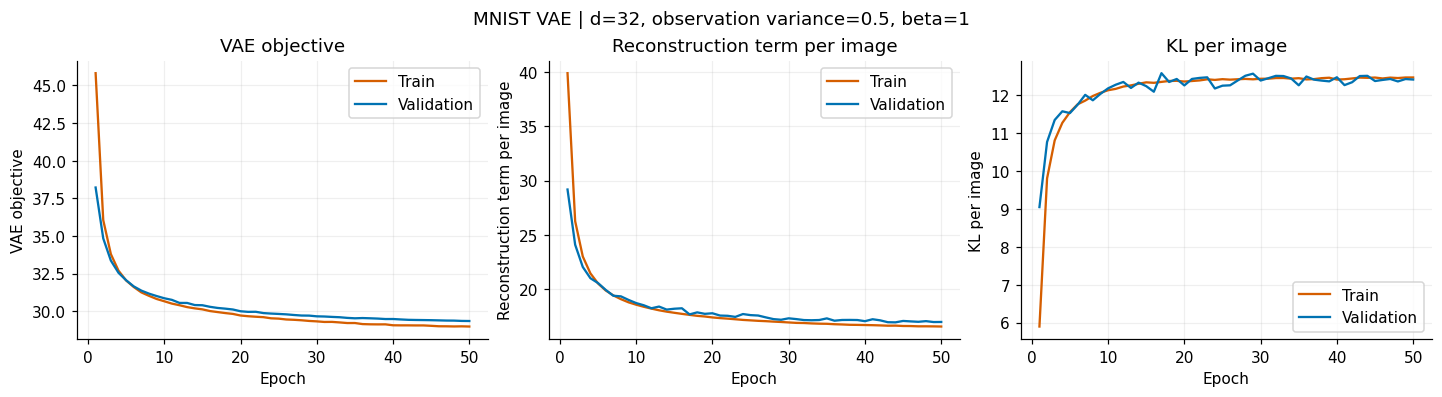

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
for ax, key, title in zip(axes, ['loss', 'reconstruction', 'kl'],
                          ['VAE objective', 'Reconstruction term per image', 'KL per image']):
    ax.plot(history_df.epoch, history_df[f'train_{key}'], label='Train', color='#D55E00')
    ax.plot(history_df.epoch, history_df[f'val_{key}'], label='Validation', color='#0072B2')
    ax.set(xlabel='Epoch', ylabel=title, title=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle(f'MNIST VAE | d={LATENT_DIM}, observation variance={OBS_VAR}, beta={BETA:g}')
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)


## 7. Evaluate held-out digits and reconstruct them

Reload the checkpoint selected by validation. The test objective still uses posterior sampling.
For a stable reconstruction display, set $z=\mu_\phi(x)$ and plot $g_\theta(\mu_\phi(x))$.
We report the pixel MSE for this deterministic choice separately. Because the decoder is
nonlinear, decoding the posterior mean generally differs from
$\mathbb E_{q_\phi(z\mid x)}[g_\theta(z)]$.

The figure uses the **first test example of each digit**, so the displayed examples are selected
independently of reconstruction quality. Original images appear above their reconstructions.


In [12]:
checkpoint = load_vae_checkpoint(best_checkpoint, model)
test_metrics = evaluate_vae(model, test_loader, OBS_VAR, BETA, noise_seed=2002)


@torch.inference_mode()
def posterior_mean_mse(model, loader):
    model.eval()
    squared_error = 0.0
    num_values = 0
    for x, _ in loader:
        x = x.to(device)
        reconstruction, _, _ = model(x, sample=False)
        squared_error += (reconstruction - x).square().sum().item()
        num_values += x.numel()
    return squared_error / num_values


test_summary = pd.DataFrame([{
    'Selected epoch': checkpoint['epoch'],
    'Test objective (constant omitted)': test_metrics['loss'],
    'Test reconstruction term per image': test_metrics['reconstruction'],
    'Test KL per image': test_metrics['kl'],
    'Test posterior-sample pixel MSE': test_metrics['mse'],
    'Test posterior-mean reconstruction pixel MSE': posterior_mean_mse(model, test_loader),
}])
display(test_summary.T.rename(columns={0: 'Value'}))
test_summary.to_csv(RUN_DIR / 'test_metrics.csv', index=False)


,Value
Selected epoch,50.000000
Test objective (constant omitted),28.868162
Test reconstruction term per image,16.418736
Test KL per image,12.449426
Test posterior-sample pixel MSE,0.020942
Test posterior-mean reconstruction pixel MSE,0.013835


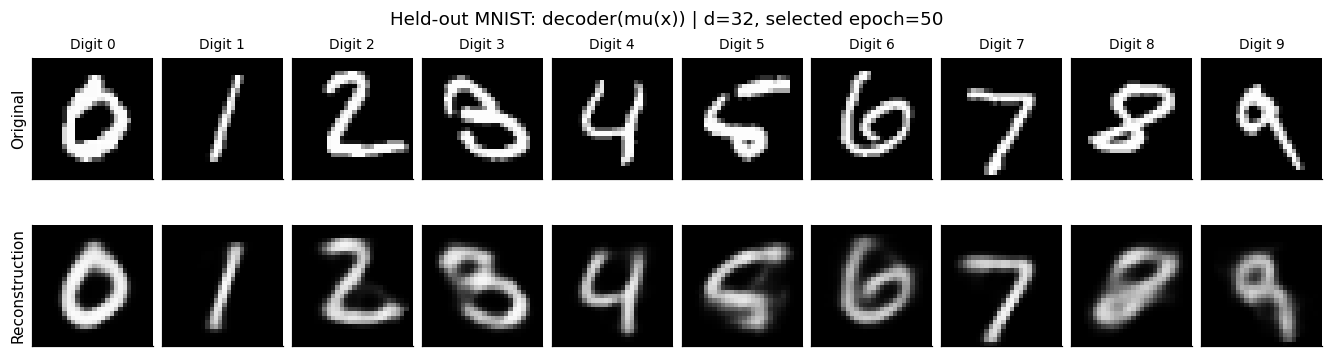

In [13]:
example_indices = [(mnist_test.targets == digit).nonzero(as_tuple=True)[0][0].item()
                   for digit in range(10)]
test_images = torch.stack([mnist_test[index][0] for index in example_indices]).to(device)
model.eval()
with torch.inference_mode():
    reconstructed, _, _ = model(test_images, sample=False)

originals = test_images.cpu()
reconstructed = reconstructed.cpu()
fig, axes = plt.subplots(2, 10, figsize=(12, 3.3), squeeze=False, layout='constrained')
for col in range(10):
    for row, images in enumerate([originals, reconstructed]):
        axes[row, col].imshow(images[col, 0].numpy(), cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[0, col].set_title(f'Digit {col}', fontsize=9)
axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruction')
fig.suptitle(f'Held-out MNIST: decoder(mu(x)) | d={LATENT_DIM}, selected epoch={checkpoint["epoch"]}')
fig.savefig(RUN_DIR / 'reconstructions.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)


## 8. Generate new digit images

Generation uses **only the prior and decoder**. Draw latent vectors independently of any input image:
$$
z^{(1)},\ldots,z^{(64)}\overset{\mathrm{iid}}\sim\mathcal N(0,I_{32}),
\qquad \widetilde x^{(i)}=g_\theta(z^{(i)}).
$$
As in the CelebA lab, display the decoder's **conditional mean** for each prior draw. We do not
add Gaussian observation noise to individual pixels. Thus these are images induced by prior
latent draws; full draws from $p_\theta(x)$ would additionally sample $x\mid z$.
The sampling scale is 1, matching the fitted standard-normal prior.

Change `NEW_DIGIT_SEED` for a different reproducible batch. The grid shows all 64 draws in order,
with no quality filtering. The model is unconditional, so a requested digit label is not supplied.
Some digits can be blurry or ambiguous; inspect both the learning curves and these outputs.

**Discuss:** Why is reconstruction usually easier than generation? What role does the KL term
play? How would changing the latent dimension or observation variance affect the balance
between reconstruction and regularization?


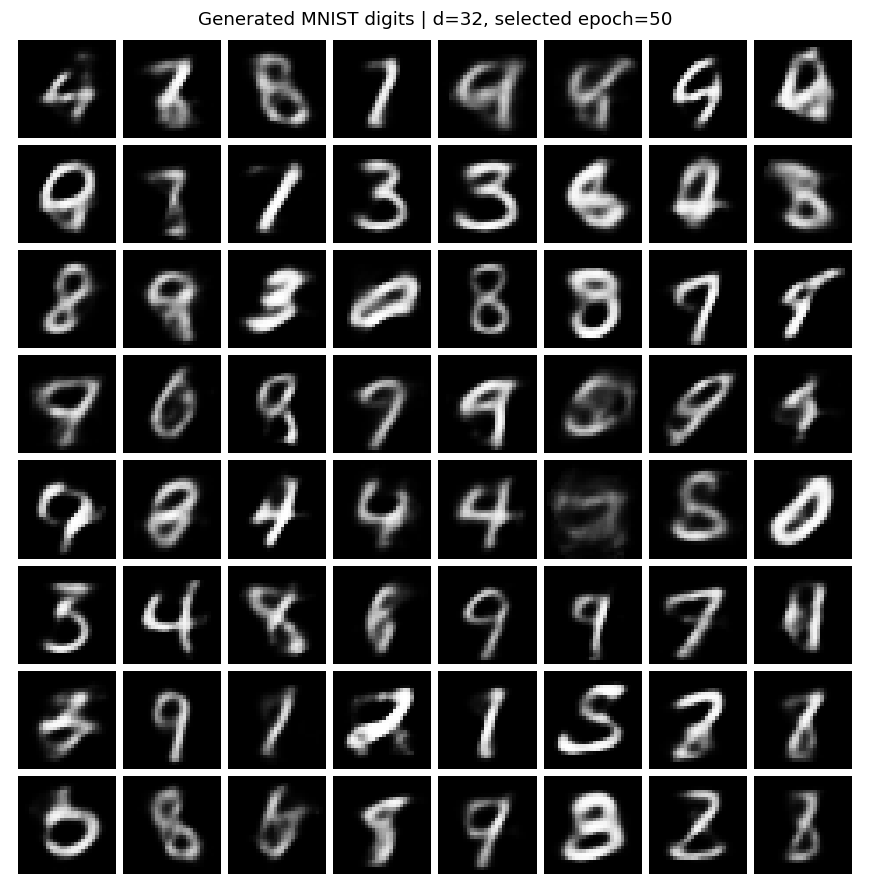

Reconstruction figure: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_vae_d32_20261015_085833_250239/reconstructions.png
Generated grid: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_vae_d32_20261015_085833_250239/generated_digits.png
Individual digits: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_vae_d32_20261015_085833_250239/generated_digits_seed_2026


In [14]:
NEW_DIGIT_SEED = 2026
NUM_NEW_DIGITS = 64

# model contains the selected, trained weights from Section 7.
# sample_digits uses fresh standard-normal vectors and never calls the encoder.
new_digits = sample_digits(model, num_digits=NUM_NEW_DIGITS, seed=NEW_DIGIT_SEED)
show_digits(new_digits,
            f'Generated MNIST digits | d={model.latent_dim}, selected epoch={checkpoint["epoch"]}',
            nrow=8, filename=RUN_DIR / 'generated_digits.png')

digit_dir = RUN_DIR / f'generated_digits_seed_{NEW_DIGIT_SEED}'
digit_dir.mkdir(exist_ok=True)
for index, digit in enumerate(new_digits):
    save_image(digit, digit_dir / f'digit_{index:03d}.png')
print('Reconstruction figure:', (RUN_DIR / 'reconstructions.png').resolve())
print('Generated grid:', (RUN_DIR / 'generated_digits.png').resolve())
print('Individual digits:', digit_dir.resolve())


## Lab notes

- This notebook keeps the original MNIST VAE's fully connected layers, ReLU hidden activations,
  sigmoid decoder mean, and Gaussian reconstruction loss, with the latent dimension set to 32.
- The presentation and workflow follow the supplied CelebA lab, including validation-based
  checkpoint selection, learning curves, held-out reconstruction, and standard-normal generation.
- Reconstruction and generation figures are displayed inline and saved under `RUN_DIR`.
  Checkpoints and CSV summaries are saved there when the notebook is run; they are separate
  from the inline output images stored in the notebook itself.
